<a href="https://colab.research.google.com/github/emazarchie-cpu/gympulse-ai./blob/main/notebooks/gympulse_model_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GYM PULSE AI


In [ ]:
import numpy as np
import pandas as pd

# Reproducibility: generate the same dataset each time
np.random.seed(42)

# Dataset size
n_members = 1000

# Generate fictional member characteristics
member_ids = [f"GP{i:04d}" for i in range(1, n_members + 1)]

membership_types = np.random.choice(
    ["Monthly", "Quarterly", "Annual"],
    size=n_members,
    p=[0.60, 0.25, 0.15]
)

membership_age_days = np.random.randint(1, 1000, n_members)

visits_previous_30_days = np.random.poisson(8, n_members)
visits_last_30_days = np.random.poisson(7, n_members)

visits_previous_30_days = np.clip(
    visits_previous_30_days, 0, 30
)

visits_last_30_days = np.clip(
    visits_last_30_days, 0, 30
)

days_since_last_visit = np.random.randint(0, 31, n_members)

renewal_due_days = np.random.randint(0, 61, n_members)

pt_sessions_attended = np.random.poisson(2, n_members)

# Create a synthetic cancellation probability.
# This is an invented simulation rule, not a real-world finding.
attendance_decline = (
    visits_previous_30_days - visits_last_30_days
)

log_odds = (
    -2.0
    + 0.07 * days_since_last_visit
    + 0.12 * attendance_decline
    - 0.10 * pt_sessions_attended
    + 0.5 * (membership_types == "Monthly")
)

cancellation_probability = 1 / (1 + np.exp(-log_odds))

# Generate fictional outcomes from the simulated probabilities
cancelled_next_30_days = np.random.binomial(
    1, cancellation_probability
)

# Assemble the dataset
gym_data = pd.DataFrame({
    "member_id": member_ids,
    "membership_type": membership_types,
    "membership_age_days": membership_age_days,
    "visits_previous_30_days": visits_previous_30_days,
    "visits_last_30_days": visits_last_30_days,
    "days_since_last_visit": days_since_last_visit,
    "renewal_due_days": renewal_due_days,
    "pt_sessions_attended": pt_sessions_attended,
    "cancelled_next_30_days": cancelled_next_30_days
})

# Save the dataset
gym_data.to_csv("gympulse_synthetic_data.csv", index=False)

# Display the results
print("GYMPULSE AI — SYNTHETIC DATASET")
print("=" * 40)

print(f"Total members: {len(gym_data)}")
print(f"Total features: {len(gym_data.columns)}")

print("\nFirst five records:")
display(gym_data.head())

print("\nCancellation outcome distribution:")
print(
    gym_data["cancelled_next_30_days"]
    .value_counts()
    .rename(index={0: "Did not cancel", 1: "Cancelled"})
)

print("\nDataset saved as gympulse_synthetic_data.csv")

GYMPULSE AI — SYNTHETIC DATASET
Total members: 1000
Total features: 9

First five records:


,member_id,membership_type,membership_age_days,visits_previous_30_days,visits_last_30_days,days_since_last_visit,renewal_due_days,pt_sessions_attended,cancelled_next_30_days
0,GP0001,Monthly,815,8,3,16,27,3,1
1,GP0002,Annual,12,9,5,8,37,2,0
2,GP0003,Quarterly,318,9,12,20,27,1,0
3,GP0004,Monthly,592,7,6,17,31,1,1
4,GP0005,Monthly,216,11,5,27,50,0,1



Cancellation outcome distribution:
cancelled_next_30_days
Did not cancel    649
Cancelled         351
Name: count, dtype: int64

Dataset saved as gympulse_synthetic_data.csv


In [ ]:
from google.colab import files

files.download("gympulse_synthetic_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Load the CSV file downloaded.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving gympulse_synthetic_data.csv to gympulse_synthetic_data (1).csv


In [ ]:
import pandas as pd

gym_data = pd.read_csv("gympulse_synthetic_data.csv")

print("Dataset loaded successfully!")
print("Number of members:", len(gym_data))
print("Number of columns:", len(gym_data.columns))

display(gym_data.head())

Dataset loaded successfully!
Number of members: 1000
Number of columns: 9


,member_id,membership_type,membership_age_days,visits_previous_30_days,visits_last_30_days,days_since_last_visit,renewal_due_days,pt_sessions_attended,cancelled_next_30_days
0,GP0001,Monthly,815,8,3,16,27,3,1
1,GP0002,Annual,12,9,5,8,37,2,0
2,GP0003,Quarterly,318,9,12,20,27,1,0
3,GP0004,Monthly,592,7,6,17,31,1,1
4,GP0005,Monthly,216,11,5,27,50,0,1


# Investigate Data

In [ ]:
# GYMPULSE AI — DATA QUALITY CHECK

print("DATASET INFORMATION")
print("=" * 40)

gym_data.info()

print("\nMISSING VALUES")
print("=" * 40)

print(gym_data.isnull().sum())

print("\nDUPLICATE MEMBER IDs")
print("=" * 40)

print(gym_data["member_id"].duplicated().sum())

print("\nNUMERICAL SUMMARY")
print("=" * 40)

display(gym_data.describe())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   member_id                1000 non-null   object
 1   membership_type          1000 non-null   object
 2   membership_age_days      1000 non-null   int64 
 3   visits_previous_30_days  1000 non-null   int64 
 4   visits_last_30_days      1000 non-null   int64 
 5   days_since_last_visit    1000 non-null   int64 
 6   renewal_due_days         1000 non-null   int64 
 7   pt_sessions_attended     1000 non-null   int64 
 8   cancelled_next_30_days   1000 non-null   int64 
dtypes: int64(7), object(2)
memory usage: 70.4+ KB

MISSING VALUES
member_id                  0
membership_type            0
membership_age_days        0
visits_previous_30_days    0
visits_last_30_days        0
days_since_last_visit      0
renewal_due_days           0
pt_sessions_attended  

,membership_age_days,visits_previous_30_days,visits_last_30_days,days_since_last_visit,renewal_due_days,pt_sessions_attended,cancelled_next_30_days
count,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,509.897000,7.94500,6.96900,14.792000,30.064000,2.062000,0.351000
std,297.825127,2.91281,2.64292,8.773124,17.484725,1.461606,0.477522
min,1.000000,1.00000,0.00000,0.000000,0.000000,0.000000,0.000000
25%,266.750000,6.00000,5.00000,7.000000,14.000000,1.000000,0.000000
50%,503.000000,8.00000,7.00000,15.000000,30.000000,2.000000,0.000000
75%,774.500000,10.00000,9.00000,22.000000,45.000000,3.000000,1.000000
max,998.000000,18.00000,18.00000,30.000000,60.000000,8.000000,1.000000


# Investigate membership cancellations
Are cancellation rates different between members with different attendance patterns?

In [ ]:
# GYMPULSE AI — CANCELLATION ANALYSIS

cancellation_rate = gym_data["cancelled_next_30_days"].mean()

print(
    f"Overall simulated cancellation rate: "
    f"{cancellation_rate:.1%}"
)

print("\nCANCELLATION RATE BY MEMBERSHIP TYPE")

display(
    gym_data.groupby("membership_type")[
        "cancelled_next_30_days"
    ].agg(["count", "mean"])
    .rename(columns={
        "count": "Number of members",
        "mean": "Simulated cancellation rate"
    })
    .style.format({
        "Simulated cancellation rate": "{:.1%}"
    })
)

print("\nAVERAGE ATTENDANCE BY CANCELLATION OUTCOME")

display(
    gym_data.groupby("cancelled_next_30_days")[
        ["visits_previous_30_days", "visits_last_30_days"]
    ].mean().rename(index={
        0: "Did not cancel",
        1: "Cancelled"
    })
)

Overall simulated cancellation rate: 35.1%

CANCELLATION RATE BY MEMBERSHIP TYPE


,Number of members,Simulated cancellation rate
membership_type,,
Annual,153,28.1%
Monthly,613,39.3%
Quarterly,234,28.6%



AVERAGE ATTENDANCE BY CANCELLATION OUTCOME


,visits_previous_30_days,visits_last_30_days
cancelled_next_30_days,,
Did not cancel,7.614792,7.183359
Cancelled,8.555556,6.572650


# first visualisation

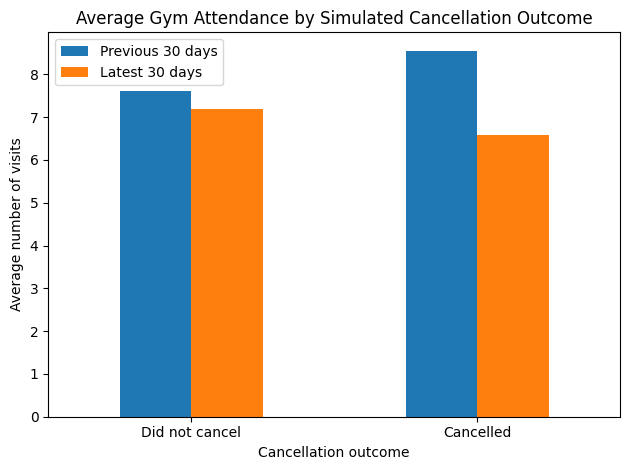

In [ ]:
import matplotlib.pyplot as plt

attendance = gym_data.groupby(
    "cancelled_next_30_days"
)[
    ["visits_previous_30_days", "visits_last_30_days"]
].mean()

attendance.index = [
    "Did not cancel",
    "Cancelled"
]

attendance.plot(kind="bar")

plt.title("Average Gym Attendance by Simulated Cancellation Outcome")
plt.xlabel("Cancellation outcome")
plt.ylabel("Average number of visits")
plt.xticks(rotation=0)
plt.legend([
    "Previous 30 days",
    "Latest 30 days"
])
plt.tight_layout()
plt.show()

# attendance_change

In [ ]:
# GYMPULSE AI — FEATURE ENGINEERING

gym_data["attendance_change"] = (
    gym_data["visits_last_30_days"]
    - gym_data["visits_previous_30_days"]
)

gym_data["attendance_declined"] = (
    gym_data["attendance_change"] < 0
).astype(int)

print("ATTENDANCE CHANGE ANALYSIS")
print("=" * 45)

print("\nAverage attendance change by outcome:")

display(
    gym_data.groupby("cancelled_next_30_days")[
        "attendance_change"
    ].agg(["mean", "median", "count"])
    .rename(index={
        0: "Did not cancel",
        1: "Cancelled"
    })
)

print("\nPercentage of members whose attendance declined:")

display(
    gym_data.groupby("cancelled_next_30_days")[
        "attendance_declined"
    ].mean()
    .mul(100)
    .round(1)
    .rename(index={
        0: "Did not cancel",
        1: "Cancelled"
    })
    .to_frame("Attendance decline (%)")
)

print("\nFeature engineering complete.")

ATTENDANCE CHANGE ANALYSIS

Average attendance change by outcome:


,mean,median,count
cancelled_next_30_days,,,
Did not cancel,-0.431433,-1.0,649
Cancelled,-1.982906,-2.0,351



Percentage of members whose attendance declined:


,Attendance decline (%)
cancelled_next_30_days,
Did not cancel,50.4
Cancelled,63.8



Feature engineering complete.


# logistic regression
learn from the features in  dataset and estimate the probability of cancellation.

In [ ]:
# GYMPULSE AI — PREPARE DATA FOR MACHINE LEARNING

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Use the dataset already loaded in gym_data.
# Create attendance features if they do not already exist.

if "attendance_change" not in gym_data.columns:
    gym_data["attendance_change"] = (
        gym_data["visits_last_30_days"]
        - gym_data["visits_previous_30_days"]
    )

if "attendance_declined" not in gym_data.columns:
    gym_data["attendance_declined"] = (
        gym_data["attendance_change"] < 0
    ).astype(int)

# Define the target variable.
target = "cancelled_next_30_days"

# Select features available in our synthetic dataset.
feature_columns = [
    "membership_type",
    "membership_age_days",
    "visits_previous_30_days",
    "visits_last_30_days",
    "days_since_last_visit",
    "renewal_due_days",
    "pt_sessions_attended",
    "attendance_change",
    "attendance_declined"
]

X = gym_data[feature_columns]
y = gym_data[target]

# Split before fitting preprocessing or the model.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Handle categorical and numerical features appropriately.
categorical_features = ["membership_type"]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Build a reproducible machine learning pipeline.
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training cancellation rate:", round(y_train.mean(), 3))
print("Testing cancellation rate:", round(y_test.mean(), 3))

Training records: 800
Testing records: 200
Training cancellation rate: 0.351
Testing cancellation rate: 0.35


In [ ]:
# TRAIN THE MODEL

model.fit(X_train, y_train)

# Generate predictions on the unseen test split.
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("GYMPULSE AI — MODEL EVALUATION")
print("=" * 45)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Did not cancel", "Cancelled"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

GYMPULSE AI — MODEL EVALUATION
Accuracy:  0.635
Precision: 0.462
Recall:    0.257
F1-score:  0.330
ROC-AUC:   0.647

Classification Report:
                precision    recall  f1-score   support

Did not cancel       0.68      0.84      0.75       130
     Cancelled       0.46      0.26      0.33        70

      accuracy                           0.64       200
     macro avg       0.57      0.55      0.54       200
  weighted avg       0.60      0.64      0.60       200


Confusion Matrix:
[[109  21]
 [ 52  18]]


# Compare the model with a simple baseline

In [ ]:
# BASELINE: FLAG MEMBERS WHOSE ATTENDANCE DECLINED

baseline_predictions = (
    X_test["attendance_change"] < 0
).astype(int)

print("RULE-BASED BASELINE")
print("=" * 35)

print(
    "Accuracy:",
    round(accuracy_score(y_test, baseline_predictions), 3)
)

print(
    "Precision:",
    round(
        precision_score(
            y_test,
            baseline_predictions,
            zero_division=0
        ),
        3
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_test,
            baseline_predictions,
            zero_division=0
        ),
        3
    )
)

print(
    "F1-score:",
    round(
        f1_score(
            y_test,
            baseline_predictions,
            zero_division=0
        ),
        3
    )
)

RULE-BASED BASELINE
Accuracy: 0.505
Precision: 0.378
Recall: 0.643
F1-score: 0.476


# Improve Recall
off all members  likely to cancel how many did the system succesfully identify

In [ ]:
y_prob = model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

print("GYMPULSE AI — THRESHOLD EXPERIMENT")
print("=" * 75)

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    accuracy = accuracy_score(
        y_test, predictions
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Accuracy: {accuracy:.3f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1-score: {f1:.3f}"
    )

GYMPULSE AI — THRESHOLD EXPERIMENT
Threshold: 0.20 | Accuracy: 0.495 | Precision: 0.406 | Recall: 0.957 | F1-score: 0.570
Threshold: 0.25 | Accuracy: 0.550 | Precision: 0.428 | Recall: 0.843 | F1-score: 0.567
Threshold: 0.30 | Accuracy: 0.575 | Precision: 0.437 | Recall: 0.743 | F1-score: 0.550
Threshold: 0.35 | Accuracy: 0.590 | Precision: 0.440 | Recall: 0.629 | F1-score: 0.518
Threshold: 0.40 | Accuracy: 0.580 | Precision: 0.410 | Recall: 0.457 | F1-score: 0.432
Threshold: 0.50 | Accuracy: 0.635 | Precision: 0.462 | Recall: 0.257 | F1-score: 0.330


# Examine the false alarms

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Apply our experimental threshold
threshold = 0.20
threshold_predictions = (y_prob >= threshold).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_test, threshold_predictions)

tn, fp, fn, tp = cm.ravel()

print("GYMPULSE AI — CONFUSION MATRIX")
print("=" * 45)
print(f"True Negatives  (correctly identified non-cancellations): {tn}")
print(f"False Positives (false cancellation alerts):             {fp}")
print(f"False Negatives (missed cancellations):                  {fn}")
print(f"True Positives  (correctly identified cancellations):    {tp}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        threshold_predictions,
        target_names=["Did not cancel", "Cancelled"],
        zero_division=0
    )
)

GYMPULSE AI — CONFUSION MATRIX
True Negatives  (correctly identified non-cancellations): 32
False Positives (false cancellation alerts):             98
False Negatives (missed cancellations):                  3
True Positives  (correctly identified cancellations):    67

Classification Report:
                precision    recall  f1-score   support

Did not cancel       0.91      0.25      0.39       130
     Cancelled       0.41      0.96      0.57        70

      accuracy                           0.49       200
     macro avg       0.66      0.60      0.48       200
  weighted avg       0.74      0.49      0.45       200



# logistic regression coefficient analysis for GymPulse AI

In [ ]:
import pandas as pd
import numpy as np

# Retrieve the fitted logistic regression model
logistic_model = model.named_steps["classifier"]

# Retrieve feature names after preprocessing
preprocessor = model.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()
coefficients = logistic_model.coef_[0]

# Build a feature importance table using absolute coefficients
importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
    "absolute_coefficient": np.abs(coefficients)
})

importance = importance.sort_values(
    "absolute_coefficient",
    ascending=False
)

print("GYMPULSE AI — LOGISTIC REGRESSION COEFFICIENTS")
print("=" * 65)
print(importance.to_string(index=False))

GYMPULSE AI — LOGISTIC REGRESSION COEFFICIENTS
                               feature  coefficient  absolute_coefficient
      numerical__days_since_last_visit     0.604727              0.604727
  categorical__membership_type_Monthly     0.344346              0.344346
   categorical__membership_type_Annual    -0.316820              0.316820
          numerical__attendance_change    -0.290113              0.290113
    numerical__visits_previous_30_days     0.255506              0.255506
        numerical__visits_last_30_days    -0.141989              0.141989
           numerical__renewal_due_days     0.105333              0.105333
        numerical__attendance_declined    -0.101794              0.101794
       numerical__pt_sessions_attended    -0.070850              0.070850
        numerical__membership_age_days     0.017522              0.017522
categorical__membership_type_Quarterly    -0.010053              0.010053


# Model B — Simplified model: A smaller set of features chosen to reduce redundancy.

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Select a smaller set of features
simplified_features = [
    "membership_type",
    "days_since_last_visit",
    "attendance_change",
    "renewal_due_days",
    "pt_sessions_attended"
]

X_simple = gym_data[simplified_features]
y_simple = gym_data["cancelled_next_30_days"]

# Use the same split as the original experiment
X_train_simple = X_simple.loc[X_train.index]
X_test_simple = X_simple.loc[X_test.index]

y_train_simple = y_simple.loc[y_train.index]
y_test_simple = y_simple.loc[y_test.index]

# Define preprocessing
categorical_features = ["membership_type"]

numerical_features = [
    "days_since_last_visit",
    "attendance_change",
    "renewal_due_days",
    "pt_sessions_attended"
]

preprocessor_simple = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

# Build and train the simplified model
simple_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_simple),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

simple_model.fit(X_train_simple, y_train_simple)

# Evaluate at the default threshold of 0.50
simple_predictions = simple_model.predict(X_test_simple)
simple_probabilities = simple_model.predict_proba(X_test_simple)[:, 1]

print("GYMPULSE AI — SIMPLIFIED MODEL")
print("=" * 45)
print(f"Accuracy:  {accuracy_score(y_test_simple, simple_predictions):.3f}")
print(f"Precision: {precision_score(y_test_simple, simple_predictions, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test_simple, simple_predictions, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test_simple, simple_predictions, zero_division=0):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_simple, simple_probabilities):.3f}")

GYMPULSE AI — SIMPLIFIED MODEL
Accuracy:  0.635
Precision: 0.463
Recall:    0.271
F1-score:  0.342
ROC-AUC:   0.655


### Model Comparison: Full vs. Simplified Logistic Regression

**Objective:** Investigate whether reducing the number of input features improves GymPulse AI's cancellation-classification performance.

**Approach:** Compared a full logistic regression model using nine input features against a simplified model using five features. Both models used the same training/test split and were evaluated at a classification threshold of 0.50.

**Results:** The simplified model maintained accuracy at 63.5%, while precision increased from 46.2% to 46.3%, recall increased from 25.7% to 27.1%, F1-score increased from 33.0% to 34.2%, and ROC-AUC increased from 0.647 to 0.655.

**Interpretation:** The simplified model achieved modest improvements across four evaluation metrics while using fewer features. This suggests that a smaller feature set may be sufficient for this initial experiment.

**Limitations:** The dataset contains 1,000 synthetically generated member records, and cancellation labels were created using an artificial probability formula. The improvements are small and have not been validated on independent real-world data. Further validation is needed before selecting a final model or making claims about real gym cancellation prediction.

In [4]:
import os

print(os.listdir("/content"))

['.config', 'gympulse_synthetic_data.csv', 'sample_data']


In [5]:
import pandas as pd

gym_data = pd.read_csv("/content/gympulse_synthetic_data.csv")

print("Dataset shape:", gym_data.shape)

gym_data.head()

Dataset shape: (1000, 9)


,member_id,membership_type,membership_age_days,visits_previous_30_days,visits_last_30_days,days_since_last_visit,renewal_due_days,pt_sessions_attended,cancelled_next_30_days
0,GP0001,Monthly,815,8,3,16,27,3,1
1,GP0002,Annual,12,9,5,8,37,2,0
2,GP0003,Quarterly,318,9,12,20,27,1,0
3,GP0004,Monthly,592,7,6,17,31,1,1
4,GP0005,Monthly,216,11,5,27,50,0,1


# Separate features and target

In [6]:
# Separate the input features from the outcome we want to predict

X = gym_data.drop(
    columns=["member_id", "cancelled_next_30_days"]
)

y = gym_data["cancelled_next_30_days"]

print("Number of features:", X.shape[1])
print("Number of records:", X.shape[0])

print("\nCancellation outcomes:")
print(y.value_counts())

Number of features: 7
Number of records: 1000

Cancellation outcomes:
cancelled_next_30_days
0    649
1    351
Name: count, dtype: int64


# training, validation, and test sets

In [7]:
from sklearn.model_selection import train_test_split

# First, reserve 20% of the data for final testing
X_remaining, X_test, y_remaining, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining 80% into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.25,
    random_state=42,
    stratify=y_remaining
)

# Display dataset sizes
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Test records:", len(X_test))

Training records: 600
Validation records: 200
Test records: 200


In [8]:
# Calculate attendance change

X["attendance_change"] = (
    X["visits_last_30_days"]
    - X["visits_previous_30_days"]
)

# Select the five features for Model B

features_b = [
    "membership_type",
    "days_since_last_visit",
    "attendance_change",
    "renewal_due_days",
    "pt_sessions_attended"
]

X_b = X[features_b].copy()

print("Model B features:")
print(X_b.columns.tolist())

print("\nDataset shape:", X_b.shape)

Model B features:
['membership_type', 'days_since_last_visit', 'attendance_change', 'renewal_due_days', 'pt_sessions_attended']

Dataset shape: (1000, 5)


# Updated Data Splits

In [9]:
from sklearn.model_selection import train_test_split

# Reserve 20% for final testing
X_remaining, X_test, y_remaining, y_test = train_test_split(
    X_b,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Divide the remaining 80% into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.25,
    random_state=42,
    stratify=y_remaining
)

# Confirm the split sizes
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (600, 5)
Validation: (200, 5)
Testing: (200, 5)


# Training GymPulse AI Model B

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify the feature types
numeric_features = [
    "days_since_last_visit",
    "attendance_change",
    "renewal_due_days",
    "pt_sessions_attended"
]

categorical_features = ["membership_type"]

# Prepare the numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Build the complete machine-learning pipeline
model_b = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Train Model B using training data only
model_b.fit(X_train, y_train)

print("GymPulse AI Model B trained successfully!")
print("Training records:", len(X_train))
print("Features:", X_train.shape[1])

GymPulse AI Model B trained successfully!
Training records: 600
Features: 5


# Evaluate Model


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict outcomes for the validation set
val_predictions = model_b.predict(X_val)

# Calculate cancellation probabilities
val_probabilities = model_b.predict_proba(X_val)[:, 1]

# Display evaluation metrics
print("VALIDATION RESULTS")
print("------------------")
print("Accuracy:", round(accuracy_score(y_val, val_predictions), 3))
print("Precision:", round(precision_score(y_val, val_predictions, zero_division=0), 3))
print("Recall:", round(recall_score(y_val, val_predictions, zero_division=0), 3))
print("F1-score:", round(f1_score(y_val, val_predictions, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_val, val_probabilities), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_predictions))

VALIDATION RESULTS
------------------
Accuracy: 0.65
Precision: 0.5
Recall: 0.271
F1-score: 0.352
ROC-AUC: 0.703

Confusion matrix:
[[111  19]
 [ 51  19]]


# Compare classification thresholds

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Candidate probability thresholds
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

results = []

for threshold in thresholds:

    # Convert probabilities into cancellation predictions
    predictions = (val_probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy_score(y_val, predictions), 3),
        "Precision": round(
            precision_score(y_val, predictions, zero_division=0), 3
        ),
        "Recall": round(
            recall_score(y_val, predictions, zero_division=0), 3
        ),
        "F1-score": round(
            f1_score(y_val, predictions, zero_division=0), 3
        ),
        "Members Flagged": int(predictions.sum())
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1-score  Members Flagged
      0.20     0.485      0.401   0.957     0.565              167
      0.25     0.560      0.433   0.829     0.569              134
      0.30     0.630      0.481   0.743     0.584              108
      0.35     0.660      0.512   0.629     0.564               86
      0.40     0.685      0.551   0.543     0.547               69
      0.50     0.650      0.500   0.271     0.352               38


#GymPulse AI — Validation Threshold Experiment
- Model: Simplified logistic regression (Model B).
- Validation records: 200.
- Thresholds evaluated: 0.20, 0.25, 0.30, 0.35, 0.40 and 0.50.
- Selected candidate: 0.30.
- Validation F1-score: 0.584.
- Validation recall: 0.743.
- Validation precision: 0.481.
- Validation accuracy: 0.630.
- Members flagged: 108 out of 200.
 Decision: Use 0.30 as the candidate threshold for the next evaluation stage because it achieved the highest F1-score among the tested thresholds

# **Final test evaluation**

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Generate cancellation probabilities for the test set
test_probabilities = model_b.predict_proba(X_test)[:, 1]

# Apply our candidate threshold
chosen_threshold = 0.30
test_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

# Calculate test metrics
print("GYMPULSE AI — FINAL TEST EVALUATION")
print("-----------------------------------")
print("Threshold:", chosen_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, test_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, test_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, test_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 3
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nMembers flagged:",
      int(test_predictions.sum()),
      "out of", len(y_test))

GYMPULSE AI — FINAL TEST EVALUATION
-----------------------------------
Threshold: 0.3
Accuracy: 0.59
Precision: 0.449
Recall: 0.757
F1-score: 0.564
ROC-AUC: 0.651

Confusion matrix:
[[65 65]
 [17 53]]

Members flagged: 118 out of 200


## Saving Trained Model

In [15]:
print("GymPulse AI is still here!")

GymPulse AI is still here!


In [16]:
print("Model B available:", "model_b" in globals())

Model B available: True


# Saving The Model

In [17]:
import joblib

model_path = "/content/gympulse_model.joblib"

joblib.dump(model_b, model_path, compress=3)

print("Model saved:", model_path)

Model saved: /content/gympulse_model.joblib


# Verifying the File

In [18]:
import os

if os.path.exists("/content/gympulse_model.joblib"):
    print("SUCCESS — Model file exists!")
    print("File size:", round(
        os.path.getsize("/content/gympulse_model.joblib") / 1024, 2
    ), "KB")
else:
    print("Model file not found.")

SUCCESS — Model file exists!
File size: 1.72 KB


# Download A copy

In [19]:
from google.colab import files

files.download("/content/gympulse_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Prediction Function


Load Saved Function


In [20]:
import joblib

model = joblib.load("/content/gympulse_model.joblib")

print("GymPulse AI model loaded successfully!")

GymPulse AI model loaded successfully!


# Create Member assessment function

In [21]:
import pandas as pd

def assess_member(
    membership_type,
    days_since_last_visit,
    visits_previous_30_days,
    visits_last_30_days,
    renewal_due_days,
    pt_sessions_attended
):
    # Calculate the change in attendance
    attendance_change = (
        visits_last_30_days - visits_previous_30_days
    )

    # Prepare the member's information
    member = pd.DataFrame([{
        "membership_type": membership_type,
        "days_since_last_visit": days_since_last_visit,
        "attendance_change": attendance_change,
        "renewal_due_days": renewal_due_days,
        "pt_sessions_attended": pt_sessions_attended
    }])

    # Estimate cancellation probability
    probability = model.predict_proba(member)[0, 1]

    # Assign a provisional risk category
    if probability >= 0.50:
        risk = "High"
    elif probability >= 0.30:
        risk = "Medium"
    else:
        risk = "Low"

    return {
        "cancellation_probability": round(float(probability), 3),
        "risk_category": risk,
        "attendance_change": attendance_change
    }

print("Member assessment function created successfully!")

Member assessment function created successfully!


# GYMPULSE AI — MEMBER ASSESSMENT

In [22]:
result = assess_member(
    membership_type="Monthly",
    days_since_last_visit=12,
    visits_previous_30_days=12,
    visits_last_30_days=4,
    renewal_due_days=5,
    pt_sessions_attended=1
)

print("GYMPULSE AI — MEMBER ASSESSMENT")
print("--------------------------------")
print("Estimated cancellation probability:",
      f"{result['cancellation_probability']:.1%}")
print("Risk category:", result["risk_category"])
print("Attendance change:", result["attendance_change"], "visits")

GYMPULSE AI — MEMBER ASSESSMENT
--------------------------------
Estimated cancellation probability: 51.5%
Risk category: High
Attendance change: -8 visits
